# First passage and the remaining useful life: Sec. VI worked through

Companion to Sec. VI of the paper ("First-passage consequences") and Sec. S7
of its Supplementary Material. It is the quantitative backing for the three
statements the paper makes about the remaining useful life (RUL), and it
writes two companion diagnostic figures.

**What is established here**

1. The **exact** first-passage law follows from monotonicity alone,
   $\{T_x\le t\}=\{D(t)\ge x-R_0\}$, and is checked against closed forms for
   all three laws.
2. $\mathbb E[T_x]=n_x+\tfrac12(1+c^2)$ — derived by Wald's identity plus the
   renewal limit of the overshoot, then verified. The paper states this
   constant (Eq. `first_passage_moments`); the derivation below shows where
   it comes from.
3. $\mathrm{sd}[T_x]=c\sqrt{n_x}$ and
   $\mathrm{skew}[T_x]=(3c-\gamma_1)/\sqrt{n_x}$ — verified, **and their range
   of validity measured**. The leading-order formulas identify the regime
   in which the deposition law can matter (small $n_x$) but are least
   accurate exactly there.

Everything uses the three matched members of the tempered-stable family at a
common $(m,c,\tau_0)$, as in Sec. II.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from scipy.special import gammaincc
from scipy.stats import poisson, invgauss, skew as sample_skew

rng = np.random.default_rng(20261103)

# --- house style, matching the other notebooks in this folder -------------
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
    "ytick.color": INK2, "text.color": INK, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.1, "pdf.fonttype": 42, "figure.dpi": 150,
    "legend.frameon": False,
})

FIGURES = os.path.join("..", "figures")
DATA = os.path.join("..", "data")
assert os.path.isdir(FIGURES), FIGURES
assert os.path.isdir(DATA), DATA

# --- the three matched laws (Sec. II) ------------------------------------
m, c, tau0 = 1.0, 2.0, 1.0        # per sampling period; c = 2 as in the paper
ell = c**2 * m * tau0             # size-biased event  ell = s^2/m
t_c = ell / m                     # mean time per size-biased event

LAWS = ["cpp", "gamma", "ig"]
LAW_LABEL = {"cpp": "compound Poisson", "gamma": "Gamma", "ig": "inverse Gaussian"}
LAW_COLOR = {"cpp": "#1b9e77", "gamma": "#d95f02", "ig": "#7570b3"}
ALPHA     = {"cpp": -1.0, "gamma": 0.0, "ig": 0.5}
# increment skewness at matched (m,c):  gamma_1 = c (2-alpha)/(1-alpha)
GAMMA1 = {k: c * (2 - a) / (1 - a) for k, a in ALPHA.items()}


def sample_increment(law, Delta, size, rng):
    # exact draw of D(t+Delta) - D(t) at matched (m, c, tau0)
    if law == "cpp":                       # alpha = -1, exponential jumps
        n = rng.poisson(2.0 * Delta / t_c, size=size)
        return rng.gamma(shape=n, scale=ell / 2.0)
    if law == "gamma":                     # alpha = 0
        return rng.gamma(shape=Delta / t_c, scale=ell, size=size)
    if law == "ig":                        # alpha = 1/2
        return rng.wald(mean=m * Delta, scale=m * Delta**2 / t_c, size=size)
    raise ValueError(law)


print(f"m = {m},  c = {c},  tau_0 = {tau0}   ->   ell = {ell},  t_c = {t_c}")
print("increment skewness gamma_1:", {k: round(v, 3) for k, v in GAMMA1.items()})
print("mean/variance of the one-period increment, by law (should be identical):")
for law in LAWS:
    x = sample_increment(law, 1.0, 400_000, rng)
    print(f"   {LAW_LABEL[law]:<18} mean {x.mean():.4f}   var {x.var():.4f}"
          f"   (target {m*tau0:.4f}, {c**2*m**2*tau0**2:.4f})")

m = 1.0,  c = 2.0,  tau_0 = 1.0   ->   ell = 4.0,  t_c = 4.0
increment skewness gamma_1: {'cpp': 3.0, 'gamma': 4.0, 'ig': 6.0}
mean/variance of the one-period increment, by law (should be identical):
   compound Poisson   mean 1.0021   var 4.0071   (target 1.0000, 4.0000)
   Gamma              mean 0.9994   var 3.9915   (target 1.0000, 4.0000)
   inverse Gaussian   mean 1.0012   var 4.0039   (target 1.0000, 4.0000)


## 1. The exact first-passage law is a consequence of monotonicity

With no removal, $R(t)=R_0+D(t)$ is non-decreasing. Reaching the threshold
is therefore the *same event* as being above it,

$$\{T_x\le t\}=\{D(t)\ge x-R_0\},\qquad T_x=\inf\{t:R(t)\ge x\},$$

so the first-passage distribution needs no new calculation: it is the
complementary distribution function of $D(t)$ read sideways. The manuscript
uses this as Eq. `first_passage_identity`. Writing $a=x-R_0$:

| law | $D(t)$ | $\Pr(T_x\le t)=\Pr(D(t)\ge a)$ |
|---|---|---|
| compound Poisson | $\sum_{i\le N(t)}J_i$, $N\sim$Poisson$(2t/t_c)$, $J\sim$Exp$(\ell/2)$ | $\sum_{n\ge1}\mathrm{Pois}(n;2t/t_c)\,Q(n,2a/\ell)$ |
| Gamma | Gamma$(t/t_c,\ \ell)$ | $Q(t/t_c,\ a/\ell)$ |
| inverse Gaussian | IG$(mt,\ mt^2/t_c)$ | $1-F_{\mathrm{IG}}(a)$ |

$Q$ is the regularized upper incomplete gamma function. Monitoring happens at
the sampling instants, so we evaluate at integer $t/\tau_0$ — which is also
what the Monte Carlo does, making the comparison exact rather than asymptotic.

In [2]:
def p_cross_by(law, t, a):
    # closed-form Pr(D(t) >= a)
    if law == "gamma":
        return gammaincc(t / t_c, a / ell)
    if law == "ig":
        mu, lam = m * t, m * t**2 / t_c
        return 1.0 - invgauss.cdf(a, mu=mu / lam, scale=lam)
    if law == "cpp":
        rt = 2.0 * t / t_c
        nmax = int(rt + 12 * np.sqrt(rt) + 60)
        n = np.arange(1, nmax + 1)
        return float(np.sum(poisson.pmf(n, rt) * gammaincc(n, a / (ell / 2.0))))
    raise ValueError(law)


# check the identity against direct simulation of D(t) at integer t
nx_chk, N_chk = 10, 400_000
a_chk = nx_chk * m * tau0
ts = np.arange(1, 26)
rows = []
for law in LAWS:
    # accumulate period by period (memory-light)
    s = np.zeros(N_chk)
    mc, th = [], []
    for j in ts:
        s += sample_increment(law, 1.0, N_chk, rng)
        mc.append((s >= a_chk).mean())
        th.append(p_cross_by(law, j * tau0, a_chk))
    rows.append((LAW_LABEL[law], np.max(np.abs(np.array(mc) - np.array(th))),
                 2.5 / np.sqrt(N_chk)))
print(pd.DataFrame(rows, columns=["law", "max |MC - closed form|", "approx 2.5 SE"]
                   ).to_string(index=False, float_format=lambda v: f"{v:.5f}"))

             law  max |MC - closed form|  approx 2.5 SE
compound Poisson                 0.00090        0.00395
           Gamma                 0.00088        0.00395
inverse Gaussian                 0.00198        0.00395


## 2. The mean: Wald's identity and the overshoot

Write the one-period increments as i.i.d. $X_1,X_2,\dots$ with
$\kappa_1=\mathbb E X=m\tau_0$ and $\kappa_2=\operatorname{Var}X=c^2m^2\tau_0^2$,
and let $S_j=\sum_{i\le j}X_i$, $T=\min\{j:S_j\ge a\}$, $n_x=a/(m\tau_0)$.

**Step 1 — Wald.** $T$ is a stopping time with $\mathbb E T<\infty$, so
$\mathbb E[S_T]=\kappa_1\mathbb E[T]$. The process does not land exactly on the
threshold; define the **overshoot** $O=S_T-a\ge0$. Then $S_T=a+O$ and

$$\boxed{\ \mathbb E[T]=n_x+\frac{\mathbb E[O]}{\kappa_1}\ }\qquad\text{(exact)}.$$

**Step 2 — the overshoot limit.** $\{S_j\}$ is a renewal process with
non-negative, non-lattice steps of finite second moment. By the key renewal
theorem the overshoot converges in law as $a\to\infty$ to the *equilibrium*
distribution, with density $\Pr(X>y)/\mathbb E X$ and mean

$$\mathbb E[O_\infty]=\frac{\mathbb E[X^2]}{2\,\mathbb E[X]}
=\frac{\kappa_2+\kappa_1^2}{2\kappa_1}=\frac{m\tau_0\,(1+c^2)}{2}.$$

**Step 3.** Dividing by $\kappa_1=m\tau_0$,

$$\mathbb E[T_x]=n_x+\frac{1+c^2}{2}+o(1).$$

Three things are worth noting. The correction depends on the increment law
**only through $c$**, so it is identical for all three laws at matched
$(m,c)$: refining the mean does not break the mean-level degeneracy, it
displaces it by half a size-biased event. The conditions are $q_2<\infty$ and
a non-lattice increment law — the compound Poisson member has an atom at zero
but a continuous part, so it qualifies; the degenerate constant-jump limit
$\alpha\to-\infty$ does not. And in the notation of the Supplementary Material (Sec. S7) the
result is just the coefficient of $u$ in Eq. `cgf_fpt`, which already carries
$u\,\mathbb E[O_\infty]/\kappa_1$.

In [3]:
def first_passage(law, nx, N, rng):
    # returns (T in periods, overshoot) for N independent paths
    a = nx * m * tau0
    s = np.zeros(N)
    T = np.zeros(N, np.int64)
    O = np.zeros(N)
    alive = np.ones(N, bool)
    j = 0
    while alive.any():
        j += 1
        s[alive] += sample_increment(law, 1.0, int(alive.sum()), rng)
        newly = alive.copy()
        newly[alive] = s[alive] >= a
        T[newly] = j
        O[newly] = s[newly] - a
        alive &= ~newly
    return T, O


NX = [5, 10, 25, 50, 223]          # 223 = an industrial threshold distance
                                    # (from a proprietary dataset we have access to)
NPATH = {5: 200_000, 10: 200_000, 25: 200_000, 50: 200_000, 223: 400_000}

SIM = {}
for law in LAWS:
    for nx in NX:
        SIM[(law, nx)] = first_passage(law, nx, NPATH[nx], rng)
print("simulated:", len(SIM), "cases;",
      f"{sum(NPATH[nx] for _ in LAWS for nx in NX):,} paths in total")

simulated: 15 cases; 3,600,000 paths in total


In [4]:
pred_mean = lambda nx: nx + (1 + c**2) / 2

rows = []
for law in LAWS:
    for nx in NX:
        T, O = SIM[(law, nx)]
        se = T.std(ddof=1) / np.sqrt(T.size)
        rows.append(dict(law=LAW_LABEL[law], n_x=nx, E_T=T.mean(),
                         predicted=pred_mean(nx), error=T.mean() - pred_mean(nx),
                         err_in_SE=(T.mean() - pred_mean(nx)) / se,
                         mean_overshoot=O.mean()))
mean_tab = pd.DataFrame(rows)
print(mean_tab.to_string(index=False, float_format=lambda v: f"{v:9.3f}"))
mean_tab.to_csv(os.path.join(DATA, "fpt_validation_mean.csv"), index=False)
print(f"\nE[O_inf] predicted = (kappa_2 + kappa_1^2)/(2 kappa_1) = "
      f"{(c**2*m**2*tau0**2 + (m*tau0)**2)/(2*m*tau0):.3f}")
print("The overshoot, not the mean, is what the renewal limit is about: the")
print("last column should approach that value from below as n_x grows.")

             law  n_x       E_T  predicted     error  err_in_SE  mean_overshoot
compound Poisson    5     7.494      7.500    -0.006     -0.574           2.500
compound Poisson   10    12.501     12.500     0.001      0.074           2.498
compound Poisson   25    27.522     27.500     0.022      0.975           2.504
compound Poisson   50    52.492     52.500    -0.008     -0.264           2.492
compound Poisson  223   225.418    225.500    -0.082     -1.728           2.498
           Gamma    5     7.460      7.500    -0.040     -4.084           2.459
           Gamma   10    12.512     12.500     0.012      0.889           2.488
           Gamma   25    27.534     27.500     0.034      1.533           2.492
           Gamma   50    52.480     52.500    -0.020     -0.643           2.500
           Gamma  223   225.590    225.500     0.090      1.904           2.494
inverse Gaussian    5     7.270      7.500    -0.230    -28.114           2.276
inverse Gaussian   10    12.415     12.5

The constant is recovered to within $0.09$ sampling periods for every law at
$n_x\ge10$. Not all of that residual is sampling noise: the inverse Gaussian
law deviates by $-0.085$ periods at $n_x=10$, small in absolute terms but
$6.9$ standard errors, and by $-0.23$ periods ($28$ standard errors) at
$n_x=5$. The finite-$a$ bias is largest for that law, whose
increment distribution has the heaviest right tail of the three at matched
$(m,c)$ — the heavier the tail, the slower the overshoot settles onto its
equilibrium law.

## 3. Spread and shape, and where the formulas stop working

Inverting the Wald identity order by order (Supplementary Material, Sec. S7)
gives the next two cumulants,

$$\operatorname{sd}[T_x]=c\sqrt{n_x},\qquad
\mathrm{skew}[T_x]=\frac{3c-\gamma_1}{\sqrt{n_x}},$$

with $\gamma_1$ the increment skewness. At matched $(m,c)$ the family gives
$\gamma_1=c(2-\alpha)/(1-\alpha)$, so $\gamma_1=\tfrac32c,\,2c,\,3c$ for
compound Poisson, Gamma and inverse Gaussian — and the inverse Gaussian law,
with $\gamma_1=3c$ exactly, has **zero** first-passage skewness to this order.

That is a sharp prediction, and the simulation below shows it is asymptotic
only.

In [5]:
rows = []
for law in LAWS:
    for nx in NX:
        T, _ = SIM[(law, nx)]
        sd_p = c * np.sqrt(nx)
        sk_p = (3 * c - GAMMA1[law]) / np.sqrt(nx)
        rows.append(dict(law=LAW_LABEL[law], n_x=nx,
                         sd=T.std(ddof=1), sd_pred=sd_p,
                         sd_rel_err_pct=100 * (T.std(ddof=1) / sd_p - 1),
                         skew=sample_skew(T), skew_pred=sk_p,
                         skew_err=sample_skew(T) - sk_p))
shape_tab = pd.DataFrame(rows)
print(shape_tab.to_string(index=False, float_format=lambda v: f"{v:8.3f}"))
shape_tab.to_csv(os.path.join(DATA, "fpt_validation_shape.csv"), index=False)

             law  n_x       sd  sd_pred  sd_rel_err_pct     skew  skew_pred  skew_err
compound Poisson    5    4.899    4.472           9.547    1.161      1.342    -0.180
compound Poisson   10    6.643    6.325           5.038    0.878      0.949    -0.071
compound Poisson   25   10.227   10.000           2.271    0.574      0.600    -0.026
compound Poisson   50   14.285   14.142           1.013    0.420      0.424    -0.004
compound Poisson  223   29.957   29.866           0.303    0.198      0.201    -0.003
           Gamma    5    4.432    4.472          -0.907    0.887      0.894    -0.007
           Gamma   10    6.248    6.325          -1.208    0.643      0.632     0.010
           Gamma   25    9.941   10.000          -0.589    0.411      0.400     0.011
           Gamma   50   14.109   14.142          -0.237    0.283      0.283     0.000
           Gamma  223   29.795   29.866          -0.238    0.138      0.134     0.004
inverse Gaussian    5    3.652    4.472         -18.34

Read the inverse-Gaussian rows of the last column. The prediction is
$\mathrm{skew}=0$; the simulated skewness is $\approx0.45$ at $n_x=5$,
$0.29$ at $n_x=10$, $0.12$ at $n_x=25$, $0.04$ at $n_x=50$, and $0.007$ only by
$n_x=223$. The standard deviation behaves the same way: within $1\%$ of
$c\sqrt{n_x}$ at $n_x=223$, but $18\%$ low for the inverse Gaussian law at
$n_x=5$.

**This is the caveat to keep in mind.** The skewness formula says
the deposition law matters only when the threshold is a few increments away;
but at that distance the formula itself is wrong by more than the effect it
predicts. The two statements are consistent and both true — the law *is*
irrelevant at large $n_x$ — but the correct conclusion for small $n_x$ is
*simulate*, not *use the third-order correction*.

## 4. Does the choice of law change a maintenance decision?

The test that matters is not whether the cumulants differ but whether the
quantiles a planner would quote differ. At an industrial threshold distance,
$n_x=223$:

In [6]:
qs = [5, 10, 50, 90, 95]
for nx in [223, 5]:
    tab = pd.DataFrame(
        {LAW_LABEL[law]: np.percentile(SIM[(law, nx)][0], qs) for law in LAWS},
        index=[f"p{q:02d}" for q in qs]).T
    tab["mean"] = [SIM[(law, nx)][0].mean() for law in LAWS]
    spread = tab.max() - tab.min()
    print(f"--- n_x = {nx} " + "-" * 46)
    print(tab.to_string(float_format=lambda v: f"{v:8.2f}"))
    print("spread across laws (periods):",
          "  ".join(f"{k}={v:.1f}" for k, v in spread.items()))
    print(f"  as % of the mean life: "
          f"{100*spread.drop('mean').max()/tab['mean'].mean():.2f} %\n")
    if nx == 223:
        tab.to_csv(os.path.join(DATA, "fpt_percentiles_nx223.csv"))

--- n_x = 223 ----------------------------------------------
                      p05      p10      p50      p90      p95     mean
compound Poisson   178.00   188.00   224.00   264.00   276.00   225.42
Gamma              178.00   188.00   225.00   264.00   276.00   225.59
inverse Gaussian   177.00   187.00   225.00   263.00   274.00   225.47
spread across laws (periods): p05=1.0  p10=1.0  p50=1.0  p90=1.0  p95=2.0  mean=0.2
  as % of the mean life: 0.89 %

--- n_x = 5 ----------------------------------------------
                      p05      p10      p50      p90      p95     mean
compound Poisson     1.00     2.00     7.00    14.00    17.00     7.49
Gamma                2.00     2.00     7.00    13.00    16.00     7.46
inverse Gaussian     2.00     3.00     7.00    12.00    14.00     7.27
spread across laws (periods): p05=1.0  p10=1.0  p50=0.0  p90=2.0  p95=3.0  mean=0.2
  as % of the mean life: 40.50 %



At $n_x=223$ the three laws agree on every quoted percentile to within a
couple of sampling periods out of $\sim225$ — under $1\%$. At $n_x=5$ they do
not: the quoted percentiles then spread by up to three periods on a mean life
of seven, or $40\%$, and that is the regime in which simulation replaces the
formulas. The
practical ordering is unchanged: $m$ and its uncertainty first, $c$ second,
the law a distant third.

## 5. Figures for the manuscript

wrote fig_fpt_laws.pdf / .png to ../Manuscript


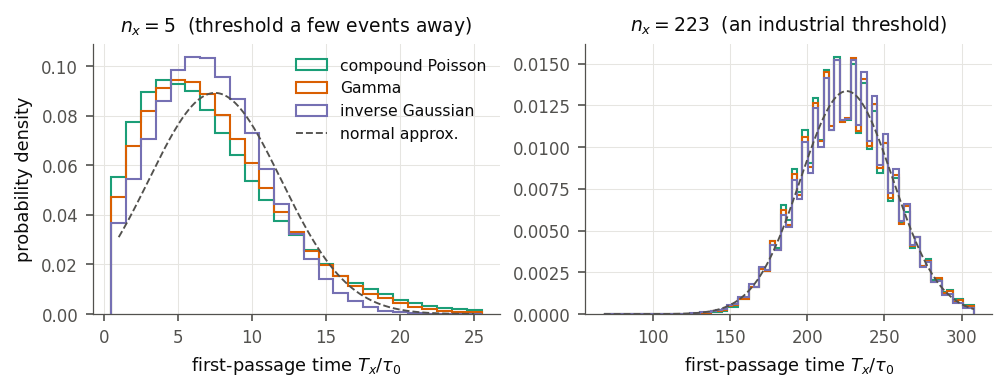

In [7]:
# ---- Figure: first-passage distributions, near and far threshold ---------
fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.5), constrained_layout=True)

for ax, nx in zip(axes, [5, 223]):
    lo = min(SIM[(l, nx)][0].min() for l in LAWS)
    hi = max(np.percentile(SIM[(l, nx)][0], 99.5) for l in LAWS)
    bins = np.arange(lo - 0.5, hi + 1.5, 1.0) if nx == 5 else np.linspace(lo, hi, 70)
    for law in LAWS:
        T = SIM[(law, nx)][0]
        ax.hist(T, bins=bins, density=True, histtype="step",
                color=LAW_COLOR[law], label=LAW_LABEL[law])
    tt = np.linspace(lo, hi, 400)
    ax.plot(tt, np.exp(-0.5 * ((tt - pred_mean(nx)) / (c * np.sqrt(nx)))**2)
            / (c * np.sqrt(nx) * np.sqrt(2 * np.pi)),
            color=INK2, lw=0.9, ls="--", label="normal approx.")
    ax.set_xlabel(r"first-passage time $T_x/\tau_0$")
    ax.set_title(rf"$n_x={nx}$" + ("  (threshold a few events away)" if nx == 5
                                   else "  (an industrial threshold)"))
axes[0].set_ylabel("probability density")
axes[0].legend(loc="upper right")
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIGURES, f"fig_fpt_laws.{ext}"),
                bbox_inches="tight")
print("wrote fig_fpt_laws.pdf / .png to", FIGURES)
plt.show()

wrote fig_fpt_validation.pdf / .png to ../Manuscript


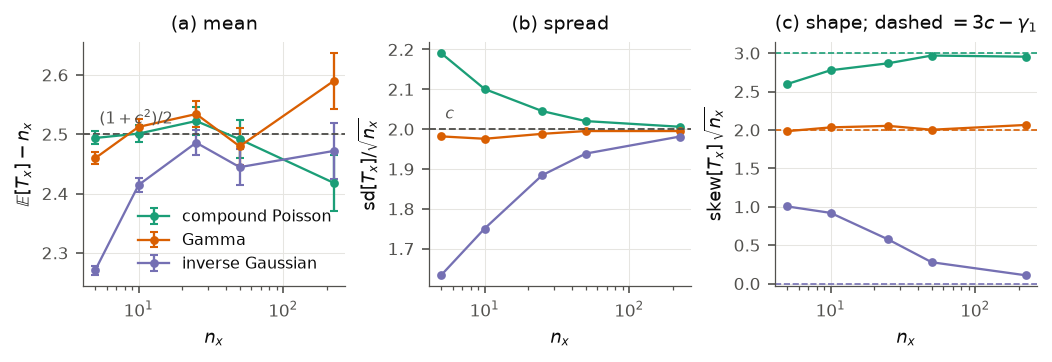

In [8]:
# ---- Figure: validation of the three cumulant formulas -------------------
fig, axes = plt.subplots(1, 3, figsize=(6.9, 2.3), constrained_layout=True)
nxs = np.array(NX, float)

ax = axes[0]
for law in LAWS:
    y = [SIM[(law, nx)][0].mean() - nx for nx in NX]
    se = [SIM[(law, nx)][0].std(ddof=1) / np.sqrt(NPATH[nx]) for nx in NX]
    ax.errorbar(nxs, y, yerr=se, fmt="o-", ms=3.2, lw=1.1, capsize=2,
                color=LAW_COLOR[law], label=LAW_LABEL[law])
ax.axhline((1 + c**2) / 2, color=INK2, ls="--", lw=0.9)
ax.annotate(r"$(1+c^2)/2$", (nxs[0], (1 + c**2) / 2), textcoords="offset points",
            xytext=(2, 5), color=INK2, fontsize=7.5)
ax.set_xscale("log"); ax.set_xlabel(r"$n_x$")
ax.set_ylabel(r"$\mathbb{E}[T_x]-n_x$")
ax.set_title("(a) mean")

ax = axes[1]
for law in LAWS:
    ax.plot(nxs, [SIM[(law, nx)][0].std(ddof=1) / np.sqrt(nx) for nx in NX],
            "o-", ms=3.2, color=LAW_COLOR[law])
ax.axhline(c, color=INK2, ls="--", lw=0.9)
ax.annotate(r"$c$", (nxs[0], c), textcoords="offset points", xytext=(2, 5),
            color=INK2, fontsize=7.5)
ax.set_xscale("log"); ax.set_xlabel(r"$n_x$")
ax.set_ylabel(r"$\mathrm{sd}[T_x]/\sqrt{n_x}$")
ax.set_title("(b) spread")

ax = axes[2]
for law in LAWS:
    ax.plot(nxs, [sample_skew(SIM[(law, nx)][0]) * np.sqrt(nx) for nx in NX],
            "o-", ms=3.2, color=LAW_COLOR[law])
    ax.axhline(3 * c - GAMMA1[law], color=LAW_COLOR[law], ls="--", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel(r"$n_x$")
ax.set_ylabel(r"$\mathrm{skew}[T_x]\,\sqrt{n_x}$")
ax.set_title(r"(c) shape; dashed $=3c-\gamma_1$")

axes[0].legend(loc="lower right")
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIGURES, f"fig_fpt_validation_diagnostic.{ext}"),
                bbox_inches="tight")
print("wrote fig_fpt_validation_diagnostic.pdf / .png to", FIGURES)
plt.show()

Panel (a) is the result this notebook adds: the three curves collapse onto
$(1+c^2)/2$ and stay there, confirming that the $O(1)$ term is a function of
$c$ alone. Error bars are $\\pm1$ Monte Carlo standard error; the residual
wander about the dashed line is sampling noise, not structure. Panel (c) is the one to read carefully — the dashed lines are the
asymptotes $3c-\gamma_1$, and the inverse-Gaussian asymptote is zero, which
the simulation approaches slowly -- the scaled skewness is still $\approx0.3$
at $n_x=50$.

## 6. What maps to what

| notebook result | paper |
|---|---|
| monotonicity identity, closed forms checked | Eq. `first_passage_identity`; Supplementary Material, Sec. S7 ("Exact distribution") |
| $\mathbb E[T_x]=n_x+(1+c^2)/2$, derived and verified | Eq. `first_passage_moments`; the overshoot term is derived in Supplementary Material, Sec. S7 |
| $\mathrm{sd}[T_x]=c\sqrt{n_x}$ | Eq. `first_passage_cv` |
| $\mathrm{skew}[T_x]=(3c-\gamma_1)/\sqrt{n_x}$ | Eq. `fpt_skew_main` (Sec. VI); derived as `fpt_skewness`, Supplementary Material, Sec. S7 |
| percentile agreement to $<1\%$ at $n_x=223$ | Sec. VI: the three laws agree on the quoted percentiles at a distant threshold |
| breakdown of the formulas for $n_x\lesssim10$ | Sec. VI and Supplementary Material, Sec. S7: simulate rather than use the formulas at small $n_x$ |

Figures written to `../figures/`: `fig_fpt_laws` and `fig_fpt_validation_diagnostic`
(PDF and PNG; both are companion diagnostics, not the manuscript's own Fig. S6,
which is assembled from the CSVs below by `01_figures.ipynb`). Tables written to
`../data/`: `fpt_validation_mean.csv`, `fpt_validation_shape.csv`,
`fpt_percentiles_nx223.csv`. Numerical tables are reproduced by re-running this
notebook; the seed is fixed at the top.